# CIFAR-100 data pipeline

Mid-evaluation notebook for the DKD project (Zhao et al., CVPR 2022).

This notebook does not train a model. It loads the real CIFAR-100 Python release and applies the preprocessing the CIFAR training recipe uses:

- train: zero-pad by 4, random 32x32 crop, horizontal flip with probability 0.5, scale to [0, 1], normalize
- test: scale to [0, 1], normalize

Labels stay integers from 0 to 99. Images stay 32×32. The training batch size in the config is 64. The full training set is used. The cells below record those choices.

The loader lives in `src/data/cifar100.py`. It is ours. The mean, std, crop, and flip match the mdistiller CIFAR-100 recipe, which we used as a reference for those constants and not as the code we submit.

Run this notebook from the repository root. The first code cell also walks up one directory if the kernel was started inside `notebooks/`.


In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

# The notebook file sits in notebooks/. The import root is the repo, one level up.
REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

from src.data.cifar100 import (
    CIFAR100_MEAN,
    CIFAR100_STD,
    load_cifar100,
    make_splits,
    preprocess_eval,
    preprocess_train,
)

print("repo root:", REPO_ROOT)
print("normalize mean:", CIFAR100_MEAN)
print("normalize std:", CIFAR100_STD)


repo root: /Users/sufyan.siddiqui/ML-Project
normalize mean: [0.5071 0.4867 0.4408]
normalize std: [0.2675 0.2565 0.2761]


In [ ]:
# Download CIFAR-100 (about 161 MB) into data/ the first time this runs.
# Skipped when data/cifar-100-python already has train, test, and meta.
from scripts.setup_project import ensure_cifar100

ensure_cifar100()

## Load the official splits

`load_cifar100` reads `data/cifar-100-python/{train,test,meta}`. Images come back as uint8 arrays shaped `(N, 32, 32, 3)`. Labels are the 100 fine classes. Coarse labels are loaded too, because the EDA uses them, but the classifier we will train uses the fine labels only.


In [14]:
data = load_cifar100(REPO_ROOT / "data" / "cifar-100-python")
splits = make_splits(data)

print("train images:", data["train_images"].shape, data["train_images"].dtype)
print("test images:", data["test_images"].shape, data["test_images"].dtype)
print("fine classes:", splits["n_fine"], " superclasses:", splits["n_coarse"])
print("train count per fine class: min", int(splits["train_fine_counts"].min()), "max", int(splits["train_fine_counts"].max()))
print("test count per fine class: min", int(splits["test_fine_counts"].min()), "max", int(splits["test_fine_counts"].max()))
print("pixel min/max:", int(data["train_images"].min()), int(data["train_images"].max()))
print("balanced train?", splits["train_balanced"], " balanced test?", splits["test_balanced"])


train images: (50000, 32, 32, 3) uint8
test images: (10000, 32, 32, 3) uint8
fine classes: 100  superclasses: 20
train count per fine class: min 500 max 500
test count per fine class: min 100 max 100
pixel min/max: 0 255
balanced train? True  balanced test? True


## A few raw images

No augmentation here. This is the file as released. Five fine classes from different superclasses, then the five classes that share the `vehicles_1` superclass. Those five are different labels, and at 32x32 they are easy to mix up. That is a property of the label set, not a bug in the loader.


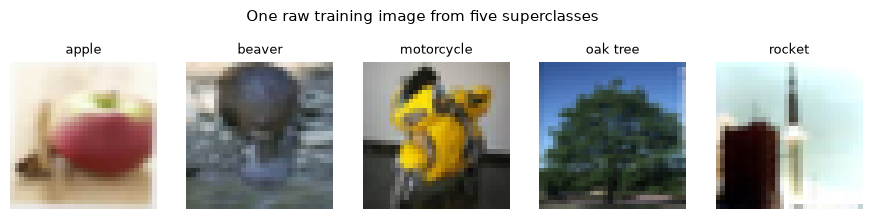

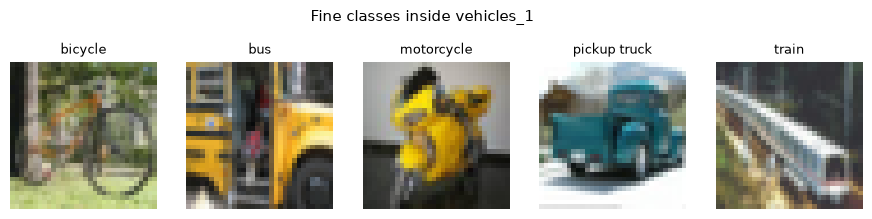

In [15]:
from typing import Any


def show_row(class_names, title):
    name_to_id = {name: i for i, name in enumerate(data["fine_names"])}
    ids = [name_to_id[name] for name in class_names]
    fig, axes = plt.subplots(1, len(ids), figsize=(2.2 * len(ids), 2.6))
    for ax, class_id in zip(axes, ids):
        index = int(np.flatnonzero(data["train_fine"] == class_id)[0])
        ax.imshow(data["train_images"][index])
        ax.set_title(data["fine_names"][class_id].replace("_", " "), fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=11)
    plt.show()

show_row(
    ["apple", "beaver", "motorcycle", "oak_tree", "rocket"],
    "One raw training image from five superclasses",
)
show_row(
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],
    "Fine classes inside vehicles_1",
)


## Preprocessing

Training view, matching the recipe:

1. Pad 4 pixels of zeros on each spatial side. The image becomes 40x40. A crop that touches the border includes that black edge.
2. Take a random 32x32 window.
3. Flip left-right with probability 0.5. There is no vertical flip.
4. Divide by 255, then subtract the CIFAR-100 mean and divide by the CIFAR-100 std.

Evaluation view skips the crop and the flip. Both functions return channel-first float32, shape `(3, 32, 32)`, which is what a PyTorch model will take later.

The seed is fixed in this cell so a rerun shows the same three training views. The figure undoes the normalization so the crop and the flip are visible. The arrays printed above the figure are the normalized ones.


raw shape: (32, 32, 3) uint8
train view shape: (3, 32, 32) float32
eval view shape: (3, 32, 32) float32
train view min/max: -1.897 / 2.025
eval view min/max: -1.790 / 2.025


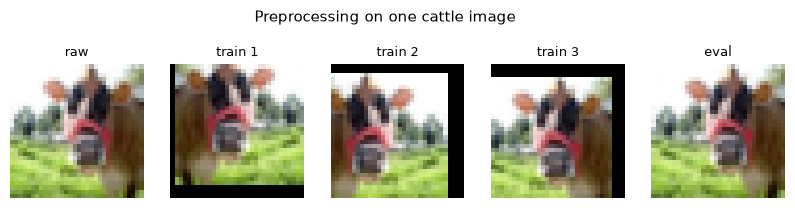

In [16]:
rng = np.random.default_rng(0)
sample = data["train_images"][0]
sample_name = data["fine_names"][int(data["train_fine"][0])]

train_views = [preprocess_train(sample, rng=rng) for _ in range(3)]
eval_view = preprocess_eval(sample)

print("raw shape:", sample.shape, sample.dtype)
print("train view shape:", train_views[0].shape, train_views[0].dtype)
print("eval view shape:", eval_view.shape, eval_view.dtype)
print("train view min/max: %.3f / %.3f" % (float(train_views[0].min()), float(train_views[0].max())))
print("eval view min/max: %.3f / %.3f" % (float(eval_view.min()), float(eval_view.max())))

def undo_normalize(chw):
    # Display only. The tensor the model sees stays normalized.
    hwc = np.transpose(chw, (1, 2, 0))
    hwc = hwc * CIFAR100_STD + CIFAR100_MEAN
    return np.clip(hwc, 0.0, 1.0)

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
shown = [sample, *[undo_normalize(v) for v in train_views], undo_normalize(eval_view)]
titles = ["raw", "train 1", "train 2", "train 3", "eval"]
for ax, image, title in zip(axes, shown, titles):
    ax.imshow(image)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.suptitle("Preprocessing on one %s image" % sample_name.replace("_", " "), fontsize=11)
plt.show()


## A small batch

Four training images, each passed through `preprocess_train`. Stacking them gives `(4, 3, 32, 32)`. Four is only so the shape is easy to read. The training config uses 64 images per batch. That batch is built in the last code cell.


In [17]:
batch_idx = [0, 100, 1000, 10000]
batch = np.stack([preprocess_train(data["train_images"][i], rng=rng) for i in batch_idx], axis=0)
labels = data["train_fine"][batch_idx]
print("batch:", batch.shape, batch.dtype)
print("labels:", labels.tolist())
print("label names:", [data["fine_names"][int(y)] for y in labels])


batch: (4, 3, 32, 32) float32
labels: [19, 55, 54, 48]
label names: ['cattle', 'otter', 'orchid', 'motorcycle']


## What this pipeline includes

This notebook follows the published CIFAR-100 recipe for the DKD paper. A step is here when that recipe uses it.


## Validation split

Some image pipelines hold out 10–20% of the training images to pick hyperparameters. This one does not. The DKD CIFAR-100 run trains on all 50,000 training images and reports accuracy on the 10,000 test images. CIFAR-100 does not ship a validation file. Holding out 5,000 images would train on a smaller set than the paper.

The schedule is already fixed: 240 epochs, batch size 64, learning rate 0.05, and DKD weights α = 1, β = 8, temperature 4.


In [18]:
print("training images used:     ", data["train_images"].shape[0])
print("validation images held out:", 0)
print("test images:               ", data["test_images"].shape[0])
print("a 10% holdout would drop:  ", data["train_images"].shape[0] // 10)


training images used:      50000
validation images held out: 0
test images:                10000
a 10% holdout would drop:   5000


## From a pixel to the array the model sees

Two transforms, in this order.

**Scale.** The file stores integers from 0 to 255 (`uint8`). Divide by 255 and store `float32`. A pixel then lies in 0.0 to 1.0.

**Channel-wise z-score.** Subtract the recipe mean and divide by the recipe standard deviation, separately for red, green, and blue. After this, values sit around 0. The constants are `(0.5071, 0.4867, 0.4408)` and `(0.2675, 0.2565, 0.2761)`. The EDA notebook recomputed the training-set statistics and they match these to three decimals, so the recipe values stay.

**Labels.** Each label is an integer from 0 to 99. PyTorch's cross-entropy takes that index. The DKD loss also uses the index to pick the target logit. A one-hot vector would be 100 numbers with a single 1. We do not build or store those.

**Layout.** On disk, and in the pictures above, the order is height, width, channel: `(32, 32, 3)`. The model array is channel, height, width: `(3, 32, 32)`. A batch adds a leading size: `(batch, 3, 32, 32)`. That is the PyTorch order. TensorFlow's usual order is channel-last. This pipeline is the PyTorch one.

The array is still NumPy. Wrapping it as a PyTorch tensor is one call, `torch.from_numpy`, and it belongs with the training loop. PyTorch is not imported here.

**Size.** ResNet32×4 and ResNet8×4 take 32×32, so the image is left at 32×32.


In [19]:
image = data["train_images"][0]
label = int(data["train_fine"][0])

scaled = image.astype(np.float32) / 255.0
normalized = (scaled - CIFAR100_MEAN) / CIFAR100_STD
channel_first = np.transpose(normalized, (2, 0, 1))

print("raw:                         ", image.shape, image.dtype)
print("raw pixel at (0, 0), RGB:    ", image[0, 0].tolist())
print("after /255, that pixel:      ", np.round(scaled[0, 0], 4))
print("after mean/std, that pixel:  ", np.round(normalized[0, 0], 4))
print("channel-first array:         ", channel_first.shape, channel_first.dtype)
print("label index:", label, " name:", data["fine_names"][label])
print("classes:", splits["n_fine"], " stored form: one integer, not a vector of", splits["n_fine"])
print("spatial size:", image.shape[0], "x", image.shape[1])


raw:                          (32, 32, 3) uint8
raw pixel at (0, 0), RGB:     [255, 255, 255]
after /255, that pixel:       [1. 1. 1.]
after mean/std, that pixel:   [1.8426 2.0012 2.0254]
channel-first array:          (3, 32, 32) float32
label index: 19  name: cattle
classes: 100  stored form: one integer, not a vector of 100
spatial size: 32 x 32


## Augmentations in the recipe

Training, and only training, does two random changes. Both are already drawn in the preprocessing figure.

1. Pad 4 black pixels on each side, then crop a random 32×32 window. The object shifts a little, so the network cannot memorize one exact position.
2. Flip left-right with probability 0.5. An apple is still an apple.

The test image is only scaled and normalized.

The crop returns the image to 32×32. No other augmentation is applied.


## Batches and shuffle

The config for ResNet32×4 → ResNet8×4 uses **64** images per step. One training batch is therefore a `float32` array of shape `(64, 3, 32, 32)` and an `int64` label array of shape `(64,)`.

Shuffle means a new order of the training indices at the start of each epoch. The file on disk is not rearranged. The test indices stay in stored order, so a later evaluation walks the same images in the same sequence.

This notebook stops once those arrays exist. Training has not started.


In [20]:
BATCH_SIZE = 64

epoch_rng = np.random.default_rng(0)
train_order = epoch_rng.permutation(len(data["train_images"]))
test_order = np.arange(len(data["test_images"]))
batch_ids = train_order[:BATCH_SIZE]

train_batch = np.stack(
    [preprocess_train(data["train_images"][int(i)], rng=epoch_rng) for i in batch_ids],
    axis=0,
)
train_labels = data["train_fine"][batch_ids]

print("training order, first 8 indices:", train_order[:8].tolist())
print("test order, first 8 indices:    ", test_order[:8].tolist())
print("train batch: ", train_batch.shape, train_batch.dtype)
print("train labels:", train_labels.shape, train_labels.dtype)
print("labels in this batch run from", int(train_labels.min()), "to", int(train_labels.max()))


training order, first 8 indices: [25461, 5892, 10377, 28814, 9578, 43565, 28804, 22391]
test order, first 8 indices:     [0, 1, 2, 3, 4, 5, 6, 7]
train batch:  (64, 3, 32, 32) float32
train labels: (64,) int64
labels in this batch run from 1 to 97


## What is ours, and what was only a reference

- Written here: reading the pickle batches, the reshape to height-width-channel, the pad and crop, the flip, the scale to [0, 1], the normalize, integer labels, and the batch of 64 in channel-first order.
- Taken from the published CIFAR-100 recipe, and checked against mdistiller: pad 4, horizontal flip, mean `(0.5071, 0.4867, 0.4408)`, std `(0.2675, 0.2565, 0.2761)`, batch size 64, train on all 50,000 images.
- Not done here: a validation holdout, one-hot labels, any augmentation beyond the pad, crop, and horizontal flip, or a training epoch.

The training-set means we measured are 0.5071, 0.4865, 0.4409. That matches the recipe to three decimals, so the recipe values stay. We did not refit normalization on a subset.
